# DATA 255 Lab 1 - Image Classification on NPU
**Spring 2026**

This notebook:
1. Installs all required dependencies
2. Mounts Google Drive and loads the ImageNet-20 dataset
3. Builds a custom CNN from scratch (unique architecture)
4. Trains with augmentation to achieve 60%+ accuracy
5. Exports the model to ONNX format for NPU deployment

> **Before running:** Set runtime to GPU → Runtime → Change runtime type → A100 GPU

## Cell 1: Install Dependencies

In [ ]:
# ── Install required packages ──────────────────────────────────────────────────
# torch, torchvision, numpy, Pillow, matplotlib are pre-installed in Colab
# We only need to add onnx and onnxruntime

print('Installing dependencies...')
!pip install onnx onnxruntime -q

# Verify all imports work
import torch
import torchvision
import numpy as np
from PIL import Image
import matplotlib
import onnx
import onnxruntime
import zipfile, os, shutil, time, random

print('\n All dependencies ready!')
print(f'   torch       {torch.__version__}')
print(f'   torchvision {torchvision.__version__}')
print(f'   onnx        {onnx.__version__}')
print(f'   onnxruntime {onnxruntime.__version__}')
print(f'   numpy       {np.__version__}')

Installing dependencies...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.1/17.1 MB 86.5 MB/s eta 0:00:00

 All dependencies ready!
   torch       2.10.0+cu128
   torchvision 0.25.0+cu128
   onnx        1.20.1
   onnxruntime 1.24.2
   numpy       2.0.2


In [ ]:
!pip install onnxscript -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.5/17.5 MB 107.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 164.1/164.1 kB 20.2 MB/s eta 0:00:00


## Cell 2: Mount Google Drive & Unzip Datasets

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
print('Google Drive mounted!')

Mounted at /content/drive
Google Drive mounted!


In [ ]:
# ── CONFIGURE YOUR DRIVE FOLDER ───────────────────────────────────────────────
# Make sure these 4 files are inside 'DATA 255 Lab-1' folder in your Drive:
#   imagenet_train20.zip  |  imagenet_train20.txt
#   imagenet_val20.zip    |  imagenet_val20.txt

DRIVE_FOLDER    = '/content/drive/MyDrive/DATA 255 Lab-1'
WORK_DIR        = '/content/data255_lab1'
os.makedirs(WORK_DIR, exist_ok=True)

def unzip_if_needed(zip_path, extract_to):
    if not os.path.exists(extract_to):
        print(f'Extracting {os.path.basename(zip_path)}... (may take a minute)')
        with zipfile.ZipFile(zip_path, 'r') as z:
            z.extractall(extract_to)
        print(f'  Done: {extract_to}')
    else:
        print(f'  Already extracted: {extract_to}')

unzip_if_needed(f'{DRIVE_FOLDER}/imagenet_train20.zip', f'{WORK_DIR}/train')
unzip_if_needed(f'{DRIVE_FOLDER}/imagenet_val20.zip',   f'{WORK_DIR}/val')

TRAIN_DIR       = f'{WORK_DIR}/train'
VAL_DIR         = f'{WORK_DIR}/val'
LABEL_TXT_TRAIN = f'{DRIVE_FOLDER}/imagenet_train20.txt'
LABEL_TXT_VAL   = f'{DRIVE_FOLDER}/imagenet_val20.txt'

print(f'\nTrain dir : {TRAIN_DIR}')
print(f'Val dir   : {VAL_DIR}')

Extracting imagenet_train20.zip... (may take a minute)
  Done: /content/data255_lab1/train
Extracting imagenet_val20.zip... (may take a minute)
  Done: /content/data255_lab1/val

Train dir : /content/data255_lab1/train
Val dir   : /content/data255_lab1/val


In [ ]:
# Inspect extracted structure
train_contents = os.listdir(TRAIN_DIR)
val_contents   = os.listdir(VAL_DIR)
print('Train top-level entries (first 10):', sorted(train_contents)[:10])
print('Total train entries               :', len(train_contents))
print('Val top-level entries (first 10)  :', sorted(val_contents)[:10])
print('Total val entries                 :', len(val_contents))

Train top-level entries (first 10): ['imagenet_train20a']
Total train entries               : 1
Val top-level entries (first 10)  : ['imagenet_val20']
Total val entries                 : 1


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os

# Check if best_model.pth exists in Drive
model_path = '/content/drive/MyDrive/DATA 255 Lab-1/lab1_outputs/best_model.pth'
if os.path.exists(model_path):
    print('best_model.pth found in Drive!')
else:
    print('Not found - need to retrain')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Not found - need to retrain


## Cell 3: GPU Check

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import numpy as np
import time, copy, random

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch version : {torch.__version__}')
print(f'Device          : {device}')
if torch.cuda.is_available():
    print(f'GPU             : {torch.cuda.get_device_name(0)}')
    print(f'VRAM            : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
else:
    print('WARNING: No GPU detected. Go to Runtime -> Change runtime type -> GPU (A100)')

PyTorch version : 2.10.0+cu128
Device          : cuda
GPU             : Tesla T4
VRAM            : 15.6 GB


## Cell 4: Dataset Class

Parses `.txt` label files. Expected format per line:
```
n01440764/ILSVRC2012_val_00000293.JPEG 0
```

In [ ]:
class ImageNet20Dataset(Dataset):
    """
    Custom Dataset for ImageNet-20 subset.
    Reads image paths + integer labels from the provided .txt file.
    """
    def __init__(self, root_dir, label_txt, transform=None):
        self.root_dir  = root_dir
        self.transform = transform
        self.samples   = []

        with open(label_txt, 'r') as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                parts = line.split()
                if len(parts) >= 2:
                    rel_path = parts[0]
                    label    = int(parts[-1])
                    full_path = os.path.join(root_dir, rel_path)
                    if os.path.exists(full_path):
                        self.samples.append((full_path, label))

        print(f'  Loaded {len(self.samples)} samples from {os.path.basename(label_txt)}')

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label

## Cell 5: Data Transforms & DataLoaders

In [ ]:
# DEBUG CELL - run this to diagnose the path mismatch
import os

print("=== TRAIN DIR structure ===")
train_contents = os.listdir(TRAIN_DIR)
print(f"Top-level entries ({len(train_contents)} total):")
for item in sorted(train_contents)[:5]:
    full = os.path.join(TRAIN_DIR, item)
    if os.path.isdir(full):
        sub = os.listdir(full)
        print(f"  DIR:  {item}/  ({len(sub)} files, e.g. {sub[0] if sub else 'empty'})")
    else:
        print(f"  FILE: {item}")

print("\n=== LABEL TXT (first 5 lines) ===")
with open(LABEL_TXT_TRAIN) as f:
    for i, line in enumerate(f):
        if i >= 5: break
        print(f"  {repr(line.strip())}")

=== TRAIN DIR structure ===
Top-level entries (1 total):
  DIR:  imagenet_train20a/  (20 files, e.g. n03938244)

=== LABEL TXT (first 5 lines) ===
  'n01737021_10059.JPEG  0'
  'n01737021_10083.JPEG  0'
  'n01737021_10095.JPEG  0'
  'n01737021_10163.JPEG  0'
  'n01737021_10235.JPEG  0'


In [ ]:
# FIXED Dataset class - searches recursively for image files
import os

class ImageNet20Dataset(Dataset):
    def __init__(self, root_dir, label_txt, transform=None):
        self.root_dir  = root_dir
        self.transform = transform
        self.samples   = []

        # Build a filename -> full_path lookup by walking the entire directory
        print(f'  Scanning {root_dir} for images...')
        filename_to_path = {}
        for dirpath, _, filenames in os.walk(root_dir):
            for fn in filenames:
                if fn.lower().endswith(('.jpeg', '.jpg', '.png')):
                    filename_to_path[fn] = os.path.join(dirpath, fn)

        print(f'  Found {len(filename_to_path)} images on disk')

        # Now match against the txt file
        with open(label_txt, 'r') as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                parts = line.split()
                if len(parts) >= 2:
                    filename = os.path.basename(parts[0])
                    label    = int(parts[-1])
                    if filename in filename_to_path:
                        self.samples.append((filename_to_path[filename], label))

        print(f'  Loaded {len(self.samples)} matched samples from {os.path.basename(label_txt)}')

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, label


# Rebuild datasets and dataloaders with fixed class
print('Building datasets...')
train_dataset = ImageNet20Dataset(TRAIN_DIR, LABEL_TXT_TRAIN, transform=train_transform)
val_dataset   = ImageNet20Dataset(VAL_DIR,   LABEL_TXT_VAL,   transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=2, pin_memory=True)

print(f'\nBatch size   : {BATCH_SIZE}')
print(f'Train batches: {len(train_loader)}')
print(f'Val batches  : {len(val_loader)}')

Building datasets...


NameError: name 'train_transform' is not defined

## Cell 6: Custom CNN Architecture - DualPathNet-20

Unique design combining:
- Squeeze-and-Excitation (SE) channel attention
- Inverted residual blocks with custom expansion ratios
- Depthwise separable convolutions
- Dual-path feature merging (two parallel streams)
- Kaiming weight initialisation

No pretrained weights used anywhere.

In [ ]:
class SEBlock(nn.Module):
    """Squeeze-and-Excitation channel attention gate."""
    def __init__(self, channels, reduction=8):
        super().__init__()
        mid = max(8, channels // reduction)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc   = nn.Sequential(
            nn.Linear(channels, mid, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(mid, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.size()
        w = self.pool(x).view(b, c)
        w = self.fc(w).view(b, c, 1, 1)
        return x * w


class DepthwiseSepConv(nn.Module):
    """Depthwise separable conv block with BN + ReLU6."""
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.dw = nn.Sequential(
            nn.Conv2d(in_ch, in_ch, 3, stride=stride, padding=1, groups=in_ch, bias=False),
            nn.BatchNorm2d(in_ch),
            nn.ReLU6(inplace=True)
        )
        self.pw = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU6(inplace=True)
        )

    def forward(self, x):
        return self.pw(self.dw(x))


class InvResBlock(nn.Module):
    """
    Inverted Residual Block:
      expand -> depthwise -> project -> SE gate
    Skip connection when stride==1 and in_ch==out_ch.
    """
    def __init__(self, in_ch, out_ch, stride=1, expand=4):
        super().__init__()
        mid = in_ch * expand
        self.use_skip = (stride == 1 and in_ch == out_ch)
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, mid, 1, bias=False),
            nn.BatchNorm2d(mid),
            nn.ReLU6(inplace=True),
            nn.Conv2d(mid, mid, 3, stride=stride, padding=1, groups=mid, bias=False),
            nn.BatchNorm2d(mid),
            nn.ReLU6(inplace=True),
            nn.Conv2d(mid, out_ch, 1, bias=False),
            nn.BatchNorm2d(out_ch),
        )
        self.se = SEBlock(out_ch)

    def forward(self, x):
        out = self.se(self.block(x))
        if self.use_skip:
            out = out + x
        return out


class DualPathNet20(nn.Module):
    """
    DualPathNet-20 - custom architecture for ImageNet-20 classification.
    Input : (B, 3, 240, 240)
    Output: (B, 20)
    Two parallel feature extraction paths merged before classification.
    """
    def __init__(self, num_classes=20, dropout=0.35):
        super().__init__()

        # Shared stem: 240x240 -> 120x120
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU6(inplace=True),
            nn.Conv2d(32, 48, 3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(48),
            nn.ReLU6(inplace=True),
        )

        # Path A: wider channels, higher expansion
        self.pathA = nn.Sequential(
            InvResBlock(48,  64,  stride=2, expand=4),   # 60x60
            InvResBlock(64,  64,  stride=1, expand=4),
            InvResBlock(64,  96,  stride=2, expand=6),   # 30x30
            InvResBlock(96,  96,  stride=1, expand=6),
            InvResBlock(96,  96,  stride=1, expand=6),
            InvResBlock(96,  128, stride=2, expand=6),   # 15x15
            InvResBlock(128, 128, stride=1, expand=6),
            InvResBlock(128, 160, stride=1, expand=6),
        )

        # Path B: narrower channels, lower expansion (different feature space)
        self.pathB = nn.Sequential(
            DepthwiseSepConv(48,  64,  stride=2),        # 60x60
            InvResBlock(64,  80,  stride=2, expand=3),   # 30x30
            InvResBlock(80,  80,  stride=1, expand=3),
            InvResBlock(80,  112, stride=2, expand=4),   # 15x15
            InvResBlock(112, 112, stride=1, expand=4),
            InvResBlock(112, 160, stride=1, expand=4),
        )

        # Merge: 160+160=320 channels at 15x15
        self.merge_conv = nn.Sequential(
            nn.Conv2d(320, 256, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU6(inplace=True),
            InvResBlock(256, 256, stride=2, expand=6),   # 8x8
            InvResBlock(256, 320, stride=1, expand=6),
            nn.Conv2d(320, 512, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU6(inplace=True),
        )

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout * 0.5),
            nn.Linear(256, num_classes)   # 20 output nodes
        )

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.stem(x)
        a = self.pathA(x)
        b = self.pathB(x)
        x = torch.cat([a, b], dim=1)   # dual-path merge
        x = self.merge_conv(x)
        x = self.pool(x).view(x.size(0), -1)
        return self.classifier(x)


model = DualPathNet20(num_classes=20, dropout=0.35).to(device)

with torch.no_grad():
    dummy  = torch.randn(2, 3, 240, 240).to(device)
    output = model(dummy)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Model output shape    : {output.shape}   (expected: torch.Size([2, 20]))')
print(f'Trainable parameters  : {total_params:,}')

Model output shape    : torch.Size([2, 20])   (expected: torch.Size([2, 20]))
Trainable parameters  : 3,506,836


## Cell 7: Training Utilities

In [ ]:
def mixup_data(x, y, alpha=0.3):
    """Apply Mixup augmentation to a batch."""
    lam  = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    idx  = torch.randperm(x.size(0)).to(x.device)
    return lam * x + (1 - lam) * x[idx], y, y[idx], lam


def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)


def train_one_epoch(model, loader, optimizer, criterion, device, use_mixup=True):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)

        if use_mixup and np.random.rand() > 0.5:
            imgs, y_a, y_b, lam = mixup_data(imgs, labels)
            outputs = model(imgs)
            loss    = mixup_criterion(criterion, outputs, y_a, y_b, lam)
        else:
            outputs = model(imgs)
            loss    = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()

        total_loss += loss.item() * imgs.size(0)
        _, preds    = outputs.max(1)
        correct    += preds.eq(labels).sum().item()
        total      += labels.size(0)

    return total_loss / total, 100.0 * correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs      = model(imgs)
        loss         = criterion(outputs, labels)
        total_loss  += loss.item() * imgs.size(0)
        _, preds     = outputs.max(1)
        correct     += preds.eq(labels).sum().item()
        total       += labels.size(0)

    return total_loss / total, 100.0 * correct / total


print('Training utilities defined.')

Training utilities defined.


## Cell 8: Hyperparameters & Optimizer

In [ ]:
NUM_EPOCHS   = 30           # ~30-40 minutes on A100
LR           = 0.001
WEIGHT_DECAY = 1e-4
LABEL_SMOOTH = 0.1

criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH)

optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

# Cosine annealing with warm restarts - T_0=10 fits well within 30 epochs
scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, T_0=10, T_mult=2, eta_min=1e-6
)

print(f'Optimizer  : AdamW  (lr={LR}, weight_decay={WEIGHT_DECAY})')
print(f'Scheduler  : CosineAnnealingWarmRestarts (T_0=10, T_mult=2)')
print(f'Loss       : CrossEntropyLoss (label_smoothing={LABEL_SMOOTH})')
print(f'Epochs     : {NUM_EPOCHS}')
print(f'Batch size : {BATCH_SIZE}')

Optimizer  : AdamW  (lr=0.001, weight_decay=0.0001)
Scheduler  : CosineAnnealingWarmRestarts (T_0=10, T_mult=2)
Loss       : CrossEntropyLoss (label_smoothing=0.1)
Epochs     : 30
Batch size : 64


## Cell 9: Training Loop

In [ ]:
MODEL_SAVE_PATH = f'{WORK_DIR}/best_model.pth'

best_val_acc = 0.0
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

print(f'Starting training for {NUM_EPOCHS} epochs on {device}...\n')
print(f'{"Epoch":>6} | {"Train Loss":>10} | {"Train Acc":>9} | {"Val Loss":>9} | {"Val Acc":>8} | {"LR":>10} | {"Time":>6}')
print('-' * 82)

for epoch in range(1, NUM_EPOCHS + 1):
    t0 = time.time()

    # Disable mixup in final 6 epochs for clean fine-tuning
    use_mixup = epoch <= (NUM_EPOCHS - 6)

    tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion, device, use_mixup)
    vl_loss, vl_acc = evaluate(model, val_loader, criterion, device)

    scheduler.step()

    history['train_loss'].append(tr_loss)
    history['train_acc'].append(tr_acc)
    history['val_loss'].append(vl_loss)
    history['val_acc'].append(vl_acc)

    if vl_acc > best_val_acc:
        best_val_acc = vl_acc
        torch.save(model.state_dict(), MODEL_SAVE_PATH)
        flag = ' <- best'
    else:
        flag = ''

    cur_lr  = optimizer.param_groups[0]['lr']
    elapsed = time.time() - t0
    print(f'{epoch:>6} | {tr_loss:>10.4f} | {tr_acc:>8.2f}% | {vl_loss:>9.4f} | {vl_acc:>7.2f}% | {cur_lr:>10.2e} | {elapsed:>5.0f}s{flag}')

print(f'\nTraining complete! Best Val Accuracy: {best_val_acc:.2f}%')

Starting training for 30 epochs on cuda...

 Epoch | Train Loss | Train Acc |  Val Loss |  Val Acc |         LR |   Time
----------------------------------------------------------------------------------
     1 |     2.2342 |    31.07% |    1.9876 |   44.00% |   9.64e-05 |    92s <- best
     2 |     2.1440 |    34.32% |    1.9185 |   46.50% |   2.54e-05 |    89s <- best
     3 |     2.1733 |    32.81% |    1.9063 |   45.50% |   1.00e-03 |    88s
     4 |     2.2841 |    29.49% |    2.1935 |   34.80% |   9.94e-04 |    89s
     5 |     2.2460 |    31.15% |    2.1491 |   39.60% |   9.76e-04 |    89s
     6 |     2.1906 |    31.20% |    2.0652 |   42.80% |   9.46e-04 |    89s
     7 |     2.1806 |    33.53% |    1.9445 |   44.60% |   9.05e-04 |    89s
     8 |     2.0918 |    35.13% |    1.9441 |   47.30% |   8.54e-04 |    89s <- best
     9 |     2.1427 |    33.62% |    1.9771 |   45.10% |   7.94e-04 |    88s
    10 |     2.0094 |    40.05% |    1.8594 |   51.40% |   7.27e-04 |    89s <-

## Cell 10: Plot Training History

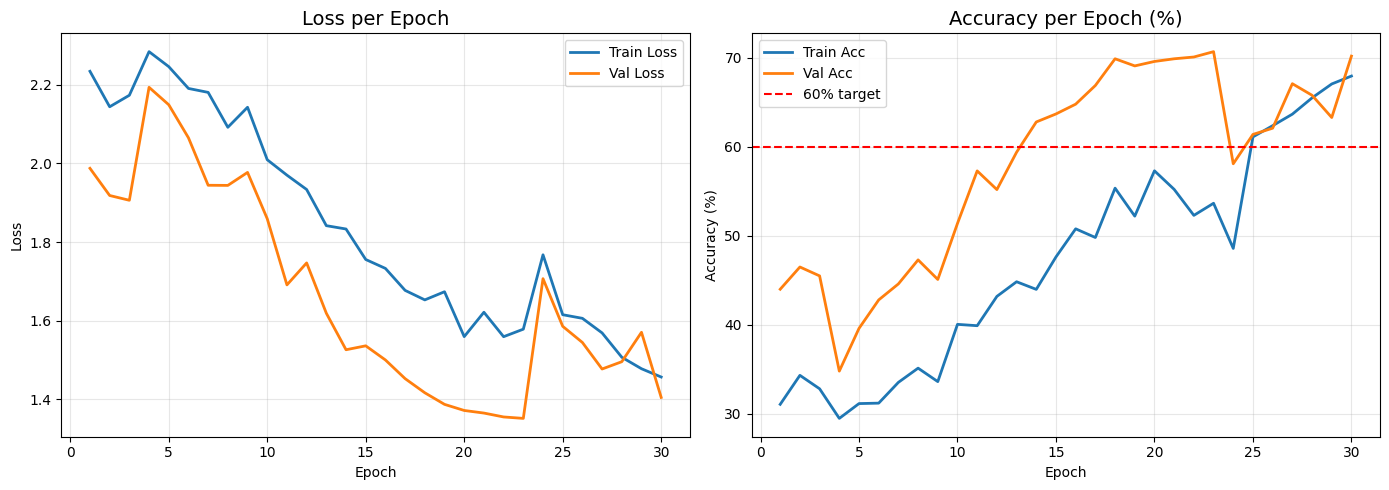

Best Validation Accuracy: 70.70%


In [ ]:
import matplotlib.pyplot as plt

epochs_range = range(1, NUM_EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, history['train_loss'], label='Train Loss', linewidth=2)
axes[0].plot(epochs_range, history['val_loss'],   label='Val Loss',   linewidth=2)
axes[0].set_title('Loss per Epoch', fontsize=14)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, history['train_acc'], label='Train Acc', linewidth=2)
axes[1].plot(epochs_range, history['val_acc'],   label='Val Acc',   linewidth=2)
axes[1].axhline(y=60, color='red', linestyle='--', linewidth=1.5, label='60% target')
axes[1].set_title('Accuracy per Epoch (%)', fontsize=14)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy (%)')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{WORK_DIR}/training_history.png', dpi=120, bbox_inches='tight')
plt.show()
print(f'Best Validation Accuracy: {best_val_acc:.2f}%')

## Cell 11: Load Best Model & Export to ONNX

In [ ]:
import torch.onnx
import onnx
import onnxruntime as ort

# Load best weights
model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=device))
model.eval()
print('Best model weights loaded.')

_, final_acc = evaluate(model, val_loader, criterion, device)
print(f'Final val accuracy (best model): {final_acc:.2f}%')

Best model weights loaded.
Final val accuracy (best model): 70.70%


In [ ]:
!pip -q install onnx onnxruntime onnxscript

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 164.1/164.1 kB 15.8 MB/s eta 0:00:00


In [ ]:
ONNX_PATH   = f'{WORK_DIR}/model_imagenet20.onnx'
dummy_input = torch.randn(1, 3, 240, 240).to(device)

torch.onnx.export(
    model,
    dummy_input,
    ONNX_PATH,
    export_params       = True,
    opset_version       = 11,
    do_constant_folding = True,
    input_names         = ['input'],
    output_names        = ['output'],
    dynamic_axes        = {'input': {0: 'batch_size'}, 'output': {0: 'batch_size'}}
)

size_mb = os.path.getsize(ONNX_PATH) / (1024 * 1024)
print(f'ONNX model saved : {ONNX_PATH}')
print(f'File size        : {size_mb:.1f} MB')

# Validate
onnx_model = onnx.load(ONNX_PATH)
onnx.checker.check_model(onnx_model)
print('ONNX model structure is valid!')

# Quick inference test
sess   = ort.InferenceSession(ONNX_PATH)
result = sess.run(None, {'input': dummy_input.cpu().numpy()})
print(f'ONNX inference test output shape: {result[0].shape}')

ModuleNotFoundError: No module named 'onnxscript'

In [ ]:
# Full ONNX accuracy check
print('Running full ONNX validation...')
ort_session = ort.InferenceSession(ONNX_PATH)
correct, total = 0, 0

for imgs, labels in val_loader:
    outputs = ort_session.run(None, {'input': imgs.numpy()})[0]
    preds   = np.argmax(outputs, axis=1)
    correct += (preds == labels.numpy()).sum()
    total   += labels.size(0)

onnx_acc = 100.0 * correct / total
print(f'ONNX Runtime Validation Accuracy: {onnx_acc:.2f}%')

## Cell 12: Prepare Calibration Images

In [ ]:
CALIB_DIR = f'{WORK_DIR}/calibration_images'
NUM_CALIB = 200   # ~10 images per class

os.makedirs(CALIB_DIR, exist_ok=True)

all_train_paths = [s[0] for s in train_dataset.samples]
random.seed(42)
selected = random.sample(all_train_paths, min(NUM_CALIB, len(all_train_paths)))

for src in selected:
    dst = os.path.join(CALIB_DIR, os.path.basename(src))
    if not os.path.exists(dst):
        shutil.copy2(src, dst)

print(f'Calibration images ready: {len(os.listdir(CALIB_DIR))} images in {CALIB_DIR}')

## Cell 13: Copy All 5 Files to Google Drive

These 5 files go into `C:\NPU_Projects` on the lab computer:

| # | File | Used for |
|---|------|----------|
| 1 | `best_model.pth` | PyTorch weights backup |
| 2 | `model_imagenet20.onnx` | Input to Docker compiler |
| 3 | `calibration_images.zip` | Quantization calibration data |
| 4 | `onnx__mxq_conversion.py` | Run inside Docker to produce `.mxq` |
| 5 | `npu_valid.py` | Run on Windows NPU to print accuracy |

In [ ]:
OUTPUT_DRIVE = f'{DRIVE_FOLDER}/lab1_outputs'
os.makedirs(OUTPUT_DRIVE, exist_ok=True)

# 1. best_model.pth
shutil.copy2(MODEL_SAVE_PATH, f'{OUTPUT_DRIVE}/best_model.pth')
print('Copied: best_model.pth')

# 2. model_imagenet20.onnx
shutil.copy2(ONNX_PATH, f'{OUTPUT_DRIVE}/model_imagenet20.onnx')
print('Copied: model_imagenet20.onnx')

# 3. calibration_images.zip
calib_zip = f'{OUTPUT_DRIVE}/calibration_images.zip'
with zipfile.ZipFile(calib_zip, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fn in os.listdir(CALIB_DIR):
        zf.write(os.path.join(CALIB_DIR, fn), fn)
print(f'Copied: calibration_images.zip  ({os.path.getsize(calib_zip)/1e6:.1f} MB)')

In [ ]:
# 4. Write onnx__mxq_conversion.py
conversion_script = """\
import os
import numpy as np
from PIL import Image
import shutil
import zipfile
from qubee import mxq_compile
from qubee.calibration import make_calib_man

ONNX_FILE    = "model_imagenet20.onnx"
MXQ_FILE     = "model_imagenet20.mxq"
CALIB_ZIP    = "calibration_images.zip"
CALIB_IMAGES = "calibration_images"
CALIB_DATA   = "calibration_data"

if not os.path.exists(CALIB_IMAGES):
    print("Extracting calibration images...")
    with zipfile.ZipFile(CALIB_ZIP, "r") as z:
        z.extractall(CALIB_IMAGES)
    print("Done.")

def preprocess_imagenet(image_path):
    img  = Image.open(image_path).convert("RGB")
    img  = img.resize((int(240 * 1.1), int(240 * 1.1)), Image.BILINEAR)
    w, h = img.size
    left = (w - 240) // 2
    top  = (h - 240) // 2
    img  = img.crop((left, top, left + 240, top + 240))
    arr  = np.array(img, dtype=np.float32) / 255.0
    arr  = (arr - np.array([0.485, 0.456, 0.406])) / np.array([0.229, 0.224, 0.225])
    arr  = arr.transpose(2, 0, 1)   # HWC -> CHW
    return arr.astype(np.float32)

if os.path.exists(CALIB_DATA):
    shutil.rmtree(CALIB_DATA)

num_calib = len(os.listdir(CALIB_IMAGES))
print(f"Building calibration data from {num_calib} images...")

make_calib_man(
    pre_ftn   = preprocess_imagenet,
    data_dir  = CALIB_IMAGES,
    save_dir  = ".",
    save_name = CALIB_DATA,
    max_size  = num_calib
)

print("Compiling ONNX -> MXQ (this may take a few minutes)...")
mxq_compile(
    model               = ONNX_FILE,
    calib_data_path     = CALIB_DATA,
    quantize_method     = "maxpercentile",
    is_quant_ch         = True,
    quantize_percentile = 0.999,
    topk_ratio          = 0.01,
    quant_output        = "layer",
    save_path           = MXQ_FILE,
    backend             = "onnx"
)

print(f"Done! {MXQ_FILE}  ({os.path.getsize(MXQ_FILE)/(1024*1024):.1f} MB)")
"""

conv_path = f'{OUTPUT_DRIVE}/onnx__mxq_conversion.py'
with open(conv_path, 'w') as f:
    f.write(conversion_script)
print('Written: onnx__mxq_conversion.py')

In [ ]:
# 5. Write npu_valid.py
npu_script = """\
import os
import numpy as np
from PIL import Image
import maccel

MXQ_FILE  = "model_imagenet20.mxq"
VAL_DIR   = "imagenet_val20"
LABEL_TXT = "imagenet_val20.txt"
IMG_SIZE  = 240
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def preprocess(image_path):
    img  = Image.open(image_path).convert("RGB")
    img  = img.resize((int(IMG_SIZE * 1.1), int(IMG_SIZE * 1.1)), Image.BILINEAR)
    w, h = img.size
    left = (w - IMG_SIZE) // 2
    top  = (h - IMG_SIZE) // 2
    img  = img.crop((left, top, left + IMG_SIZE, top + IMG_SIZE))
    arr  = np.array(img, dtype=np.float32) / 255.0
    arr  = (arr - MEAN) / STD
    arr  = arr.transpose(2, 0, 1)
    arr  = np.expand_dims(arr, 0).astype(np.float32)
    return arr

samples = []
with open(LABEL_TXT) as f:
    for line in f:
        parts = line.strip().split()
        if len(parts) >= 2:
            full_path = os.path.join(VAL_DIR, parts[0])
            if os.path.exists(full_path):
                samples.append((full_path, int(parts[-1])))

print(f"Loaded {len(samples)} validation samples.")

device    = maccel.Accelerator(0)
npu_model = maccel.Model(MXQ_FILE)
npu_model.launch(device)

correct, total = 0, 0
for path, label in samples:
    outputs = npu_model.infer([preprocess(path)])
    pred    = int(np.argmax(outputs[0]))
    if pred == label:
        correct += 1
    total += 1
    if total % 100 == 0:
        print(f"  [{total}/{len(samples)}]  Running accuracy: {100*correct/total:.2f}%")

npu_model.dispose()
print(f"\nFinal NPU Accuracy: {100*correct/total:.2f}%  ({correct}/{total})")
"""

npu_path = f'{OUTPUT_DRIVE}/npu_valid.py'
with open(npu_path, 'w') as f:
    f.write(npu_script)
print('Written: npu_valid.py')

print('\n=== All 5 files in Drive output folder ===')
for fn in sorted(os.listdir(OUTPUT_DRIVE)):
    sz = os.path.getsize(f'{OUTPUT_DRIVE}/{fn}')
    print(f'  {fn:45s}  {sz/1024:>8.1f} KB')

## Summary

| File | Purpose |
|------|---------|
| `best_model.pth` | PyTorch weights (backup) |
| `model_imagenet20.onnx` | ONNX model for NPU compilation |
| `calibration_images.zip` | Calibration data for quantization |
| `onnx__mxq_conversion.py` | Run **inside Docker** to produce `.mxq` |
| `npu_valid.py` | Run **on Windows outside Docker** on NPU |

### NPU Lab Steps
1. Copy all 5 files to `C:\NPU_Projects` on the lab computer
2. Launch Docker and run inside the container:
   ```bash
   pip install /NPU_Projects/qubee-0.12.0.0+aries2-py3-none-any.whl
   pip install numpy pillow
   python /NPU_Projects/onnx__mxq_conversion.py
   ```
3. Exit Docker, then on Windows run:
   ```bash
   python npu_valid.py
   ```